# Predicting Income Level from Census Data
**Project 3 — Machine Learning Foundations**

## 1. Problem Definition

**Task type:** Supervised learning — **binary classification**.

**Goal:** Predict whether a person's annual income is **above \$50K** (`>50K`) or **at or below \$50K** (`<=50K`) from demographic and employment attributes recorded in the 1994 U.S. Census.

**Dataset:** *Adult* (also known as "Census Income"), UCI Machine Learning Repository — https://archive.ics.uci.edu/dataset/2/adult (Becker & Kohavi, 1996).
The original `adult.data` (train) and `adult.test` files were combined into a single `adult.csv` with a header row; no values were altered.

**Why this framing:** the target is a clearly defined categorical label, the classes are imbalanced (which makes metric selection meaningful), and the data contains sensitive attributes (sex, race) that allow us to examine model fairness.

## 2. Setup
Import libraries and fix a random seed so results are reproducible.

In [25]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42  # used everywhere randomness is involved, for reproducibility

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

numpy 2.5.5 | pandas 3.1.1 | scikit-learn 1.9.1


## 3. Load and Inspect the Dataset

In [26]:
# Load the raw CSV. skipinitialspace guards against stray spaces after commas.
df = pd.read_csv("adult.csv", skipinitialspace=True)

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 48,842 rows x 15 columns


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


### 3.1 Column names and data types

In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      48842 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48842 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [28]:
# Split columns by type — this drives preprocessing later
TARGET = "income"
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in df.select_dtypes(exclude="number").columns if c != TARGET]

print("Numeric features    :", numeric_cols)
print("Categorical features:", categorical_cols)
print("Target              :", TARGET)

Numeric features    : ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Target              : income


In [29]:
# Summary statistics for numeric features
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


### 3.2 Data quality checks

In [30]:
# 1) Missing values: the UCI files encode "unknown" as '?', so pandas does not see them as NaN
question_marks = (df == "?").sum()
print("Cells containing '?':")
print(question_marks[question_marks > 0])
print(f"\nRows with at least one '?': {(df == '?').any(axis=1).sum():,} "
      f"({(df == '?').any(axis=1).mean():.1%} of rows)")
print(f"True NaN values: {df.isna().sum().sum()}")

Cells containing '?':
workclass         2799
occupation        2809
native-country     857
dtype: int64

Rows with at least one '?': 3,620 (7.4% of rows)
True NaN values: 0


In [31]:
# 2) Inconsistent target labels: the test file adds a trailing period ('>50K.')
df[TARGET].value_counts()

income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64

In [32]:
# 3) Exact duplicate rows
print(f"Duplicate rows: {df.duplicated().sum():,}")

Duplicate rows: 29


In [33]:
# 4) Skewed numeric features: capital gain / loss are zero for most people
for col in ["capital-gain", "capital-loss"]:
    print(f"{col}: {(df[col] == 0).mean():.1%} zeros, max = {df[col].max():,}")

capital-gain: 91.7% zeros, max = 99,999
capital-loss: 95.3% zeros, max = 4,356


In [34]:
# 5) Redundant columns: education (text) and education-num (ordinal code) carry the same information
codes_per_level = df.groupby("education")["education-num"].nunique()
print(f"Each education level maps to exactly one education-num code: {(codes_per_level == 1).all()}")
df.groupby("education")["education-num"].first().sort_values().to_frame().T

Each education level maps to exactly one education-num code: True


education,Preschool,1st-4th,5th-6th,7th-8th,9th,10th,11th,12th,HS-grad,Some-college,Assoc-voc,Assoc-acdm,Bachelors,Masters,Prof-school,Doctorate
education-num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16


### 3.3 Data quality notes

- **Hidden missing values.** Missing entries are stored as `'?'` in `workclass`, `occupation` and `native-country` (7.4% of rows affected), not as `NaN`. They must be converted before imputation.
- **Inconsistent labels.** The target has four spellings (`<=50K`, `<=50K.`, `>50K`, `>50K.`) because the original test file appends a period. These will be normalized to two classes.
- **Duplicates.** 29 exact duplicate rows exist (<0.1%). With no person identifier, they could be genuinely different people with identical attributes, so this is noted rather than assumed to be an error.
- **Skewed features.** `capital-gain` and `capital-loss` are zero for the vast majority of rows, with a long right tail; the maximum of 99,999 looks like a recording cap rather than a real value.
- **Redundancy.** `education` and `education-num` map one-to-one, so only one should be kept. `fnlwgt` is a census sampling weight rather than a personal attribute.

## 4. Data Cleaning

Fix the issues found in Section 3 that are *errors in the file*, not modelling choices:

1. Normalize the four target spellings to two classes and encode the target as `1 = >50K`, `0 = <=50K`.
2. Convert `'?'` to a real missing value (`NaN`) so that imputation can handle it inside the pipeline later.
3. Keep the 29 duplicate rows. With no person ID, identical rows may be different people, and removing 0.06% of the data has no material effect either way.

Missing values are **not** filled in here. Filling them before the train/test split would let information from the test set leak into training (Kaufman et al., 2012), so imputation happens inside the preprocessing pipeline in Section 6.

In [35]:
clean = df.copy()

# 1) Normalize target labels: strip the trailing '.' added in the original test file
clean[TARGET] = clean[TARGET].str.rstrip(".")
clean[TARGET] = (clean[TARGET] == ">50K").astype(int)   # 1 = >50K, 0 = <=50K

# 2) Turn '?' placeholders into proper missing values
clean = clean.replace("?", np.nan)

print("Target classes after cleaning:", sorted(clean[TARGET].unique()))
print("\nMissing values per column (now visible to pandas):")
print(clean.isna().sum()[lambda s: s > 0])

Target classes after cleaning: [np.int64(0), np.int64(1)]

Missing values per column (now visible to pandas):
workclass         2799
occupation        2809
native-country     857
dtype: int64


## 5. Exploratory Data Analysis
Figures are also saved to `figures/` for use in the report.

In [36]:
from pathlib import Path

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    """Save a figure to figures/<name>.png at report quality."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

### 5.1 Target balance

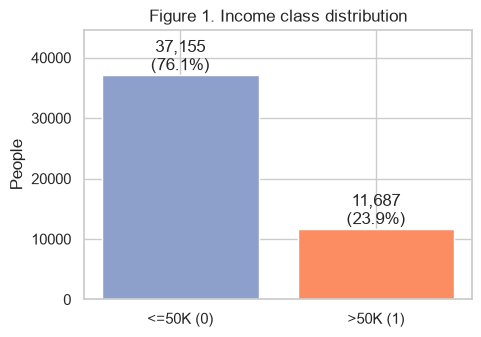

A model that always predicts '<=50K' would already be 76.1% accurate.


In [37]:
counts = clean[TARGET].value_counts().sort_index()
shares = counts / counts.sum()

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["<=50K (0)", ">50K (1)"], counts, color=["#8da0cb", "#fc8d62"])
for i, (n, p) in enumerate(zip(counts, shares)):
    ax.text(i, n, f"{n:,}\n({p:.1%})", ha="center", va="bottom")
ax.set_ylabel("People")
ax.set_title("Figure 1. Income class distribution")
ax.set_ylim(0, counts.max() * 1.2)
save(fig, "fig1_class_balance")
plt.show()

print(f"A model that always predicts '<=50K' would already be {shares[0]:.1%} accurate.")

The classes are imbalanced (about 3 to 1). Accuracy alone would therefore be a misleading measure, because a model that never predicts `>50K` still scores about 76%. Evaluation in Section 8 will focus on precision, recall, F1 and ROC-AUC instead.

### 5.2 Numeric features by income class

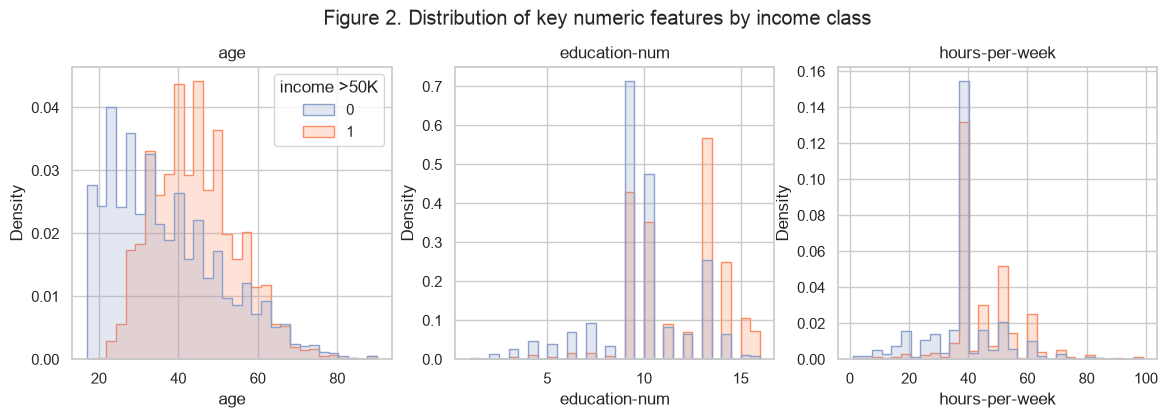

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
income,,,,,,
<=50K,36.9,190039.6,9.6,147.0,54.2,38.8
>50K,44.3,188470.6,11.6,4042.2,193.5,45.5


In [38]:
plot_cols = ["age", "education-num", "hours-per-week"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, plot_cols):
    sns.histplot(data=clean, x=col, hue=TARGET, stat="density", common_norm=False,
                 bins=30, element="step", ax=ax, palette=["#8da0cb", "#fc8d62"])
    ax.set_title(col)
axes[0].get_legend().set_title("income >50K")
for ax in axes[1:]:
    ax.get_legend().remove()
fig.suptitle("Figure 2. Distribution of key numeric features by income class", y=1.03)
save(fig, "fig2_numeric_by_class")
plt.show()

# Mean of each numeric feature per class, as a compact table
clean.groupby(TARGET)[numeric_cols].mean().round(1).rename(index={0: "<=50K", 1: ">50K"})

Higher earners are older on average, have more years of education, and work longer hours. All three features should be useful predictors.

### 5.3 Share of high earners across categories

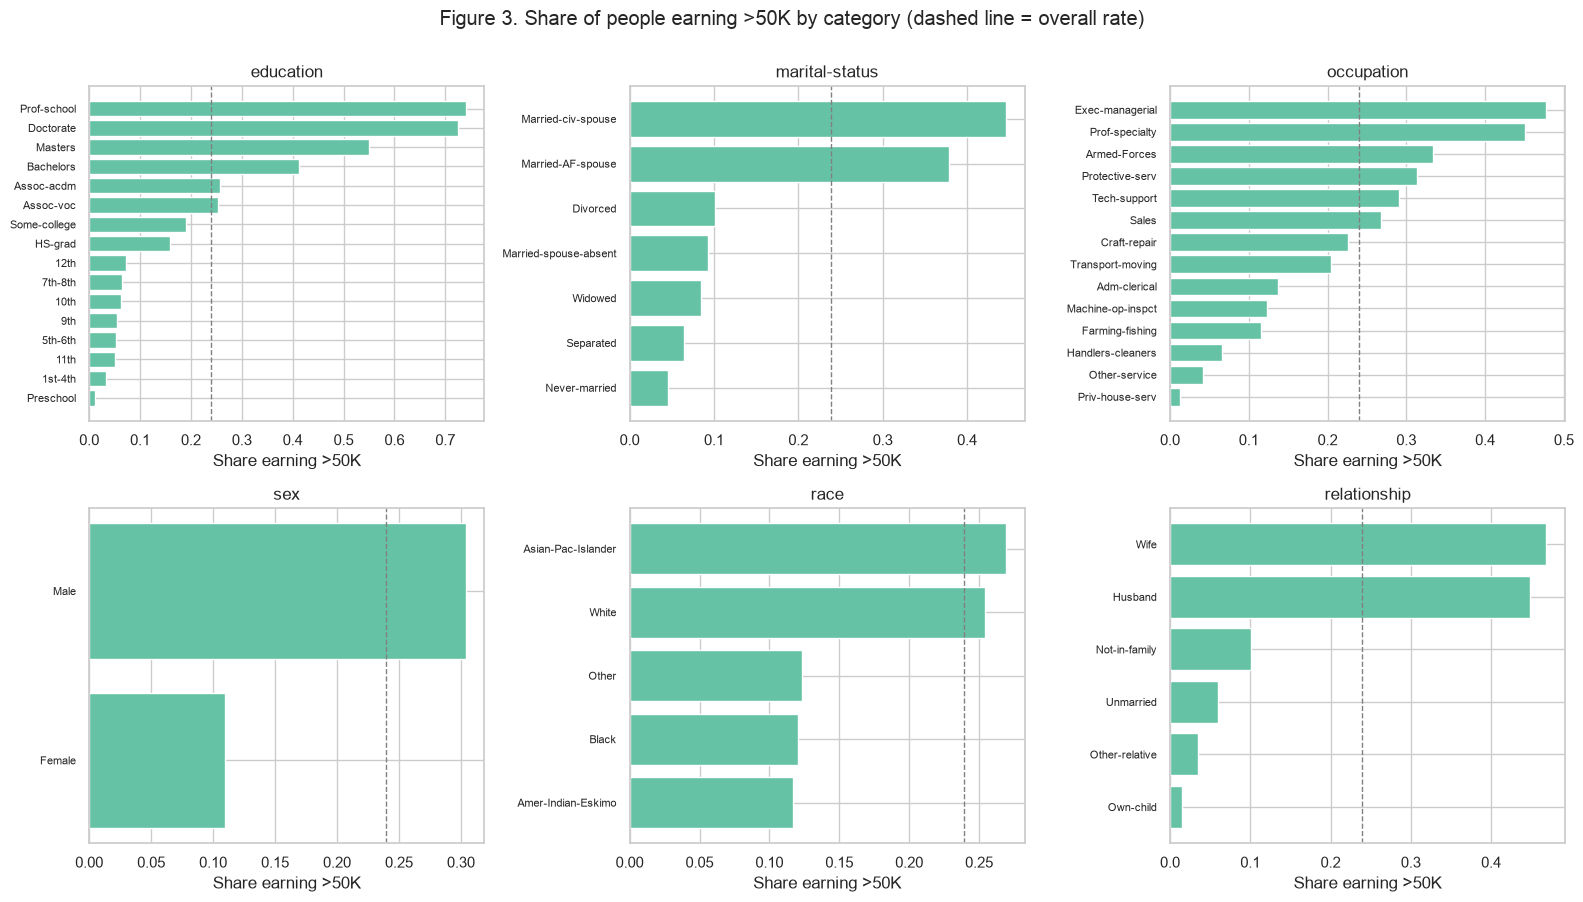

In [39]:
cat_plot_cols = ["education", "marital-status", "occupation", "sex", "race", "relationship"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
overall_rate = clean[TARGET].mean()
for ax, col in zip(axes.ravel(), cat_plot_cols):
    rate = clean.groupby(col)[TARGET].mean().sort_values()
    ax.barh(rate.index, rate.values, color="#66c2a5")
    ax.axvline(overall_rate, color="grey", ls="--", lw=1)
    ax.set_title(col)
    ax.set_xlabel("Share earning >50K")
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Figure 3. Share of people earning >50K by category (dashed line = overall rate)", y=1.0)
fig.tight_layout()
save(fig, "fig3_rate_by_category")
plt.show()

### 5.4 Sensitive attributes

In [40]:
# Group sizes and high-earner rates for the sensitive attributes we will audit later
for col in ["sex", "race"]:
    summary = clean.groupby(col)[TARGET].agg(count="size", share_over_50k="mean")
    summary["share_of_data"] = summary["count"] / len(clean)
    display(summary.sort_values("count", ascending=False).style.format(
        {"count": "{:,}", "share_over_50k": "{:.1%}", "share_of_data": "{:.1%}"}))

,count,share_over_50k,share_of_data
sex,,,
Male,"32,650",30.4%,66.8%
Female,"16,192",10.9%,33.2%


,count,share_over_50k,share_of_data
race,,,
White,"41,762",25.4%,85.5%
Black,"4,685",12.1%,9.6%
Asian-Pac-Islander,"1,519",26.9%,3.1%
Amer-Indian-Eskimo,470,11.7%,1.0%
Other,406,12.3%,0.8%


- Only about 11% of women in the data earn more than \$50K, compared with about 30% of men. Women make up only one third of the rows.
- About 85% of rows are labelled `White`. Groups such as `Amer-Indian-Eskimo` and `Other` have only a few hundred rows each, so any metric calculated for them will be noisy.
- `relationship` partly encodes sex (`Husband` / `Wife`), so removing the `sex` column alone would not stop the model from learning sex-related patterns.

These gaps reflect 1994 labour-market inequality recorded in the census. A model trained on this data can reproduce them, so Section 9 checks the model's errors separately for each group.

### 5.5 Correlation between numeric features

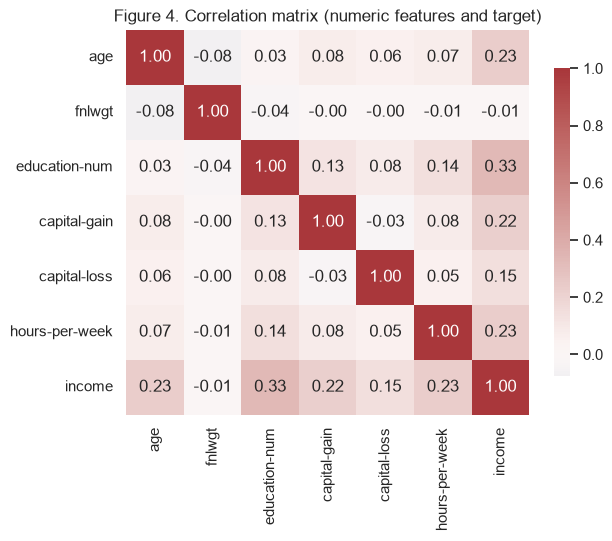

In [41]:
fig, ax = plt.subplots(figsize=(6.5, 5))
corr = clean[numeric_cols + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Figure 4. Correlation matrix (numeric features and target)")
save(fig, "fig4_correlation")
plt.show()

No pair of numeric features is strongly correlated, so multicollinearity is not a concern for a linear model. `fnlwgt` has almost no correlation with the target, which matches its role as a census sampling weight rather than a personal attribute.

## 6. Preprocessing

### 6.1 Feature selection

| Decision | Reason |
|---|---|
| Drop `education` | Duplicates `education-num` one-to-one (Section 3.2). The ordinal number keeps the ordering of education levels. |
| Drop `fnlwgt` | A survey sampling weight that describes how the census sample was drawn, not the person (UCI `adult.names`). It has near-zero correlation with the target. |
| Keep `sex` and `race` as features for the main model | The data records them, and removing them alone does not remove their influence (see `relationship`). Section 9 audits fairness and compares against a model trained without them. |
| `log1p` transform on `capital-gain` and `capital-loss` | Over 90% zeros with a long right tail. The log compresses extreme values so they do not dominate a linear model. |

In [42]:
X = clean.drop(columns=[TARGET, "education", "fnlwgt"])
y = clean[TARGET]

num_features = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
log_features = ["capital-gain", "capital-loss"]          # subset of num_features to log-transform
cat_features = ["workclass", "marital-status", "occupation", "relationship",
                "race", "sex", "native-country"]
SENSITIVE = ["sex", "race"]

assert set(num_features + cat_features) == set(X.columns)
print(f"X: {X.shape[0]:,} rows x {X.shape[1]} features | positive rate = {y.mean():.1%}")

X: 48,842 rows x 12 features | positive rate = 23.9%


### 6.2 Train / test split

An 80/20 split, **stratified** on the target so that both sets keep the same 76/24 class ratio. The test set is held back and used only once, for final evaluation. Model tuning uses cross-validation on the training set only (Hastie et al., 2009).

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,} rows | positive rate {y_train.mean():.1%}")
print(f"Test : {len(X_test):,} rows | positive rate {y_test.mean():.1%}")

Train: 39,073 rows | positive rate 23.9%
Test : 9,769 rows | positive rate 23.9%


### 6.3 Preprocessing pipeline

All transformations are wrapped in a single scikit-learn `ColumnTransformer`. Inside cross-validation and on the test set, the imputers, scaler and encoder are **fitted on training data only**, which prevents data leakage (Pedregosa et al., 2011).

- **Numeric:** median imputation, then `log1p` for the two capital columns, then standardization (mean 0, std 1). Scaling matters for logistic regression, because the regularization penalty treats all coefficients on the same scale.
- **Categorical:** most-frequent imputation, then one-hot encoding. Categories seen fewer than 20 times in training (for example rare countries) are grouped into a single "infrequent" column, and categories never seen in training are ignored safely at prediction time.

In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

def build_preprocessor(num_cols, cat_cols, log_cols=()):
    """Return a ColumnTransformer that imputes, transforms and encodes the given columns."""
    plain_num = [c for c in num_cols if c not in log_cols]
    log_num = [c for c in num_cols if c in log_cols]

    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    skewed = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                 sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric, plain_num),
        ("log", skewed, log_num),
        ("cat", categorical, cat_cols),
    ])

preprocessor = build_preprocessor(num_features, cat_features, log_features)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('log', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [45]:
# Sanity check: fit on the training set only and inspect the result
X_train_prepared = preprocessor.fit_transform(X_train)
feature_names = preprocessor.get_feature_names_out()

print(f"Columns before: {X_train.shape[1]}  ->  after encoding: {X_train_prepared.shape[1]}")
print(f"Missing values after preprocessing: {np.isnan(X_train_prepared).sum()}")
pd.DataFrame(X_train_prepared, columns=feature_names, index=X_train.index).head()

Columns before: 12  ->  after encoding: 80
Missing values after preprocessing: 0


,num__age,num__education-num,num__hours-per-week,log__capital-gain,log__capital-loss,cat__workclass_Federal-gov,cat__workclass_Local-gov,cat__workclass_Private,cat__workclass_Self-emp-inc,cat__workclass_Self-emp-not-inc,cat__workclass_State-gov,cat__workclass_infrequent_sklearn,cat__marital-status_Divorced,cat__marital-status_Married-AF-spouse,cat__marital-status_Married-civ-spouse,cat__marital-status_Married-spouse-absent,cat__marital-status_Never-married,cat__marital-status_Separated,cat__marital-status_Widowed,cat__occupation_Adm-clerical,cat__occupation_Craft-repair,cat__occupation_Exec-managerial,cat__occupation_Farming-fishing,cat__occupation_Handlers-cleaners,cat__occupation_Machine-op-inspct,cat__occupation_Other-service,cat__occupation_Priv-house-serv,cat__occupation_Prof-specialty,cat__occupation_Protective-serv,cat__occupation_Sales,cat__occupation_Tech-support,cat__occupation_Transport-moving,cat__occupation_infrequent_sklearn,cat__relationship_Husband,cat__relationship_Not-in-family,cat__relationship_Other-relative,cat__relationship_Own-child,cat__relationship_Unmarried,cat__relationship_Wife,cat__race_Amer-Indian-Eskimo,cat__race_Asian-Pac-Islander,cat__race_Black,cat__race_Other,cat__race_White,cat__sex_Female,cat__sex_Male,cat__native-country_Cambodia,cat__native-country_Canada,cat__native-country_China,cat__native-country_Columbia,cat__native-country_Cuba,cat__native-country_Dominican-Republic,cat__native-country_Ecuador,cat__native-country_El-Salvador,cat__native-country_England,cat__native-country_France,cat__native-country_Germany,cat__native-country_Greece,cat__native-country_Guatemala,cat__native-country_Haiti,cat__native-country_Hong,cat__native-country_India,cat__native-country_Iran,cat__native-country_Ireland,cat__native-country_Italy,cat__native-country_Jamaica,cat__native-country_Japan,cat__native-country_Mexico,cat__native-country_Nicaragua,cat__native-country_Peru,cat__native-country_Philippines,cat__native-country_Poland,cat__native-country_Portugal,cat__native-country_Puerto-Rico,cat__native-country_South,cat__native-country_Taiwan,cat__native-country_Thailand,cat__native-country_United-States,cat__native-country_Vietnam,cat__native-country_infrequent_sklearn
34495,-0.120090,1.138210,-0.844835,-0.296054,-0.220527,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
18591,1.268245,-0.804025,-0.038454,-0.296054,4.466051,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
12562,1.049034,-0.415578,-0.441645,-0.296054,-0.220527,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
552,2.437369,-1.192472,-0.038454,-0.296054,-0.220527,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3479,0.537542,1.526657,-0.199731,-0.296054,-0.220527,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


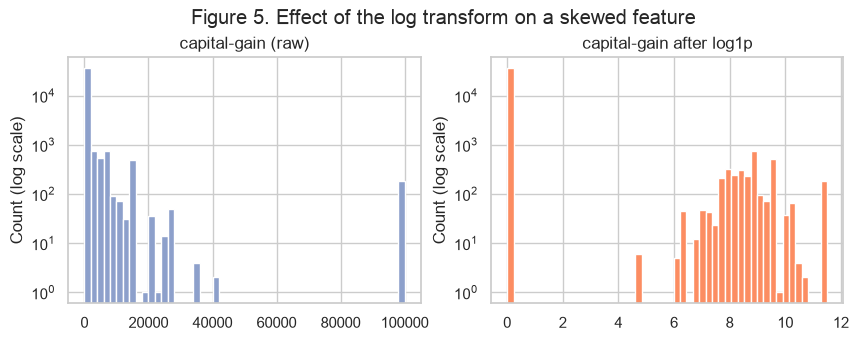

In [46]:
# Confirm the log transform tamed the skew of capital-gain
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(X_train["capital-gain"], bins=50, color="#8da0cb")
axes[0].set_title("capital-gain (raw)")
axes[1].hist(np.log1p(X_train["capital-gain"]), bins=50, color="#fc8d62")
axes[1].set_title("capital-gain after log1p")
for ax in axes:
    ax.set_yscale("log")
    ax.set_ylabel("Count (log scale)")
fig.suptitle("Figure 5. Effect of the log transform on a skewed feature", y=1.03)
save(fig, "fig5_log_transform")
plt.show()

### 6.4 Preprocessing summary

- 48,842 rows; the target is binary with 23.9% positives.
- Drop 2 columns (`education`, `fnlwgt`), leaving 12 input features: 5 numeric and 7 categorical. These become the one-hot encoded matrix shown above.
- Missing values are filled inside the pipeline using statistics learned from the training set only.
- The test set (20%, stratified) stays untouched until final evaluation.

## 7. Model Selection and Training

Three models are trained, from simplest to most flexible:

| Model | Why it is included |
|---|---|
| **Majority-class baseline** (`DummyClassifier`) | Always predicts `<=50K`. Any useful model must beat it. |
| **Logistic regression** | A linear model for binary outcomes. It is fast, well understood, and its coefficients can be read directly as the direction and strength of each feature's effect (James et al., 2021). |
| **Random forest** | An ensemble of decision trees (Breiman, 2001). It captures non-linear effects and interactions (for example, education mattering more for married people) without manual feature engineering. |

**Tuning.** Each model's settings (hyperparameters) are chosen by 5-fold stratified cross-validation on the training set only. The selection metric is **F1 for the `>50K` class**. F1 balances precision and recall, which suits an imbalanced target better than accuracy (Saito & Rehmsmeier, 2015). Both models also try `class_weight="balanced"`, which makes mistakes on the minority class count more during training.

In [47]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(estimator, num_cols=num_features, cat_cols=cat_features):
    """Full model = preprocessing + estimator, so every CV fold refits preprocessing on its own training data."""
    return Pipeline([
        ("prep", build_preprocessor(num_cols, cat_cols, log_features)),
        ("model", estimator),
    ])

def tune(name, estimator, param_grid):
    """Grid-search a pipeline with 5-fold CV on the training set, optimizing F1."""
    search = GridSearchCV(make_pipeline(estimator), param_grid, cv=cv, scoring="f1",
                          n_jobs=-1, return_train_score=True)
    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    best = search.cv_results_["mean_train_score"][search.best_index_]
    print(f"{name}: best CV F1 = {search.best_score_:.3f} (train F1 = {best:.3f}) "
          f"| {len(search.cv_results_['params'])} settings x 5 folds in {elapsed:.0f}s")
    print(f"  best settings: {search.best_params_}")
    return search

### 7.1 Baseline

In [48]:
baseline = make_pipeline(DummyClassifier(strategy="most_frequent"))
baseline.fit(X_train, y_train)
print(f"Baseline training accuracy: {baseline.score(X_train, y_train):.3f}")

Baseline training accuracy: 0.761


### 7.2 Logistic regression
`C` controls regularization strength. Smaller values shrink the coefficients more, which reduces overfitting.

In [49]:
lr_search = tune(
    "Logistic regression",
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    {"model__C": [0.01, 0.1, 1, 10],
     "model__class_weight": [None, "balanced"]},
)
log_reg = lr_search.best_estimator_

Logistic regression: best CV F1 = 0.671 (train F1 = 0.672) | 8 settings x 5 folds in 4s
  best settings: {'model__C': 1, 'model__class_weight': 'balanced'}


### 7.3 Random forest
`max_depth` and `min_samples_leaf` limit how detailed each tree can become. Deep trees with tiny leaves tend to memorize the training data.

In [50]:
rf_search = tune(
    "Random forest",
    RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    {"model__max_depth": [12, 20, None],
     "model__min_samples_leaf": [1, 5],
     "model__class_weight": [None, "balanced_subsample"]},
)
forest = rf_search.best_estimator_

/Users/home/Projects/MachineLearningFoundations/.venv/lib/python3.15/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/home/Projects/MachineLearningFoundations/.venv/lib/python3.15/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/home/Projects/MachineLearningFoundations/.venv/lib/python3.15/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib worker

Random forest: best CV F1 = 0.699 (train F1 = 0.794) | 12 settings x 5 folds in 44s
  best settings: {'model__class_weight': 'balanced_subsample', 'model__max_depth': 20, 'model__min_samples_leaf': 1}


In [51]:
# Cross-validation results side by side (training data only — the test set is still untouched)
cv_summary = pd.DataFrame({
    "Model": ["Logistic regression", "Random forest"],
    "CV F1 (mean)": [lr_search.best_score_, rf_search.best_score_],
    "CV F1 (std)": [lr_search.cv_results_["std_test_score"][lr_search.best_index_],
                    rf_search.cv_results_["std_test_score"][rf_search.best_index_]],
    "Train F1": [lr_search.cv_results_["mean_train_score"][lr_search.best_index_],
                 rf_search.cv_results_["mean_train_score"][rf_search.best_index_]],
}).set_index("Model")
cv_summary["Train - CV gap"] = cv_summary["Train F1"] - cv_summary["CV F1 (mean)"]
cv_summary.round(3)

,CV F1 (mean),CV F1 (std),Train F1,Train - CV gap
Model,,,,
Logistic regression,0.671,0.002,0.672,0.001
Random forest,0.699,0.004,0.794,0.095


**Training observations.**
- Both models were tuned towards `class_weight="balanced"`, which confirms that the class imbalance matters.
- The random forest reaches a higher cross-validated F1 (0.699 vs 0.671).
- The forest scores 0.794 on its own training folds but 0.699 on unseen folds. This gap of about 0.10 shows some overfitting: the trees memorize part of the training data. The CV score, not the training score, is the honest estimate of performance.
- Logistic regression shows almost no gap. Its simpler, linear form limits it (higher bias) but it is very stable (low variance). This is the classic bias–variance trade-off (Hastie et al., 2009).

## 8. Model Evaluation on the Test Set

The models are now scored on the 9,769 held-out test rows, which none of them has seen.

**Metrics used** (Saito & Rehmsmeier, 2015; Pedregosa et al., 2011):
- **Precision.** Of the people the model flags as `>50K`, how many really are.
- **Recall.** Of the people who really earn `>50K`, how many the model finds.
- **F1.** The harmonic mean of precision and recall, so it is high only if both are high.
- **ROC-AUC.** How well the model *ranks* high earners above low earners, across all decision thresholds. 0.5 means random, 1.0 means perfect.
- **PR-AUC (average precision).** Like ROC-AUC, but focused on the minority class, which makes it more informative under imbalance.
- **Accuracy** and **balanced accuracy** are reported for completeness. Accuracy is flattered by the 76% majority class.

In [52]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)

models = {"Baseline (majority)": baseline, "Logistic regression": log_reg, "Random forest": forest}

def evaluate(model, X_, y_):
    """Return the standard metric set for one fitted model on one dataset."""
    pred = model.predict(X_)
    proba = model.predict_proba(X_)[:, 1]
    return {
        "Accuracy": accuracy_score(y_, pred),
        "Balanced acc.": balanced_accuracy_score(y_, pred),
        "Precision": precision_score(y_, pred, zero_division=0),
        "Recall": recall_score(y_, pred),
        "F1": f1_score(y_, pred),
        "ROC-AUC": roc_auc_score(y_, proba),
        "PR-AUC": average_precision_score(y_, proba),
    }

results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in models.items()}).T
results.round(3)

,Accuracy,Balanced acc.,Precision,Recall,F1,ROC-AUC,PR-AUC
Baseline (majority),0.761,0.500,0.000,0.000,0.000,0.500,0.239
Logistic regression,0.801,0.812,0.557,0.831,0.667,0.896,0.726
Random forest,0.833,0.830,0.611,0.825,0.702,0.918,0.802


**Test-set results.**
- **Baseline.** The majority-class baseline reaches 76.1% accuracy while finding *zero* high earners (recall 0, F1 0). This shows why accuracy alone is not used to judge the models.
- **Random forest.** It is the best model on every metric: F1 0.702, ROC-AUC 0.918, PR-AUC 0.802.
- **Logistic regression.** It is close behind (F1 0.667, ROC-AUC 0.896), so most of the signal in this data is captured by a simple linear model.
- **Generalization.** The forest's test F1 (0.702) is almost identical to its cross-validated F1 (0.699). The model generalizes as expected despite the train/CV gap noted above.

In [53]:
# Pick the final model by cross-validated F1 (not by test score, to keep the test set honest)
best_name = cv_summary["CV F1 (mean)"].idxmax()
best_model = models[best_name]
print(f"Selected model: {best_name}\n")
print(classification_report(y_test, best_model.predict(X_test), target_names=["<=50K", ">50K"], digits=3))

Selected model: Random forest

              precision    recall  f1-score   support

       <=50K      0.938     0.835     0.884      7431
        >50K      0.611     0.825     0.702      2338

    accuracy                          0.833      9769
   macro avg      0.775     0.830     0.793      9769
weighted avg      0.860     0.833     0.840      9769



### 8.1 Confusion matrices

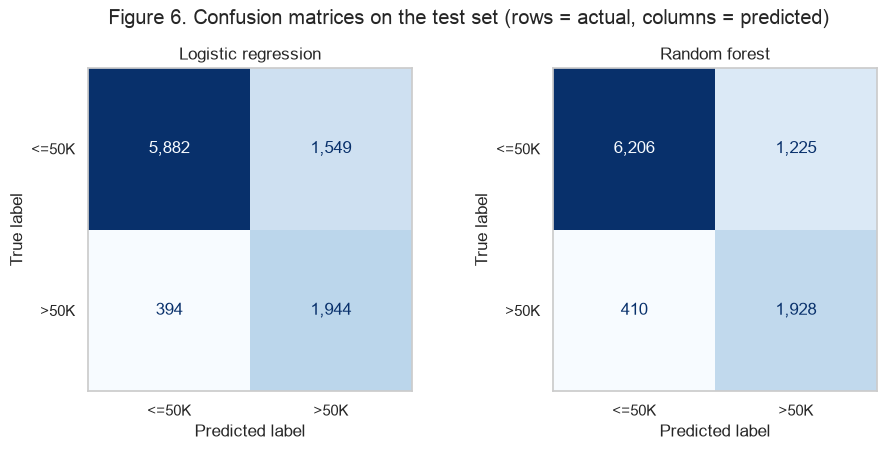

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, name in zip(axes, ["Logistic regression", "Random forest"]):
    ConfusionMatrixDisplay.from_estimator(models[name], X_test, y_test, display_labels=["<=50K", ">50K"],
                                          cmap="Blues", values_format=",", ax=ax, colorbar=False)
    ax.grid(False)  # the seaborn theme grid would otherwise cut through the cells
    ax.set_title(name)
fig.suptitle("Figure 6. Confusion matrices on the test set (rows = actual, columns = predicted)", y=1.02)
save(fig, "fig6_confusion_matrices")
plt.show()

Reading the random forest matrix:
- It correctly finds **1,928 of the 2,338** real high earners (recall 82.5%).
- It also wrongly flags **1,225** people who earn `<=50K`. So when it says `>50K` it is right about 61% of the time (precision).
- This leaning towards false positives is a direct result of `class_weight="balanced_subsample"`: the model was told that missing a high earner is worse than a false alarm.
- Compared with logistic regression, the forest makes about 320 fewer false alarms at almost the same recall.

### 8.2 ROC and precision–recall curves

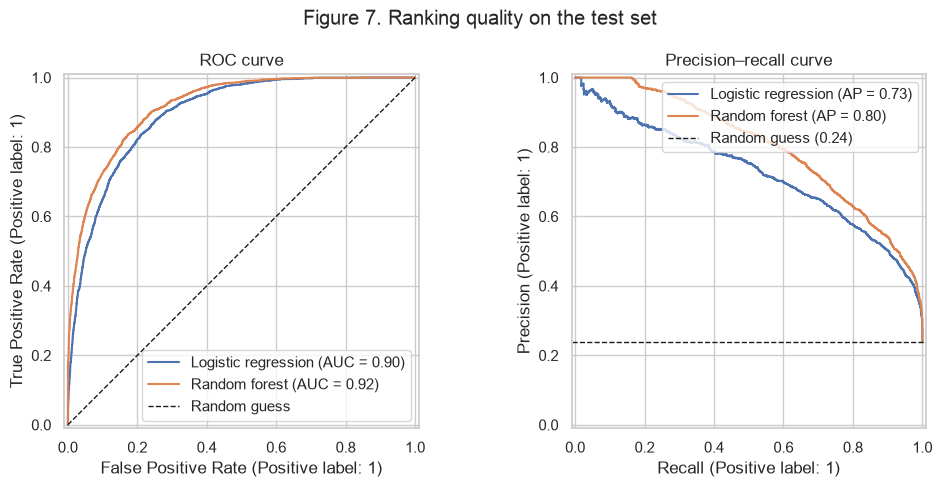

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for name in ["Logistic regression", "Random forest"]:
    RocCurveDisplay.from_estimator(models[name], X_test, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(models[name], X_test, y_test, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Random guess ({y_test.mean():.2f})")
axes[1].legend(loc="upper right")
axes[0].set_title("ROC curve")
axes[1].set_title("Precision–recall curve")
fig.suptitle("Figure 7. Ranking quality on the test set", y=1.02)
save(fig, "fig7_roc_pr_curves")
plt.show()

Both curves sit far from the random-guess lines. The random forest's curves lie above the logistic regression's almost everywhere, so its advantage holds across all thresholds and is not tied to the default of 0.5. ROC-AUC 0.92 means that if one high earner and one low earner are picked at random, the forest gives the high earner the higher score 92% of the time.

### 8.3 Decision threshold trade-off

By default a person is classified as `>50K` when the predicted probability is at least 0.5. Moving this threshold trades precision against recall. The right setting depends on which mistake is more costly in the application. The threshold is shown here for interpretation only; the reported results keep the default.

In [56]:
proba_best = best_model.predict_proba(X_test)[:, 1]
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (proba_best >= t).astype(int)
    rows.append({"Threshold": t,
                 "Precision": precision_score(y_test, pred_t, zero_division=0),
                 "Recall": recall_score(y_test, pred_t),
                 "F1": f1_score(y_test, pred_t),
                 "Share flagged >50K": pred_t.mean()})
threshold_table = pd.DataFrame(rows).set_index("Threshold")
print(f"{best_name} — effect of the decision threshold on the test set")
threshold_table.round(3)

Random forest — effect of the decision threshold on the test set


,Precision,Recall,F1,Share flagged >50K
Threshold,,,,
0.3,0.504,0.924,0.653,0.439
0.4,0.558,0.880,0.683,0.378
0.5,0.611,0.825,0.702,0.323
0.6,0.677,0.740,0.707,0.262
0.7,0.786,0.613,0.689,0.187


Raising the threshold to 0.6 gives a slightly higher F1 (0.707) and a better balance: precision 0.68, recall 0.74. Lowering it to 0.3 finds 92% of high earners, but half of the people it flags are wrong. Because the threshold was not chosen during cross-validation, the default of 0.5 is kept for all reported results, to avoid tuning on the test set.

### 8.4 Which features drive the predictions?

**Permutation importance** measures how much test-set F1 drops when one feature's values are randomly shuffled, which breaks that feature's link to the target (Breiman, 2001; Pedregosa et al., 2011). It works for any model and is computed on the original 12 columns, so each one-hot group counts as a single feature.

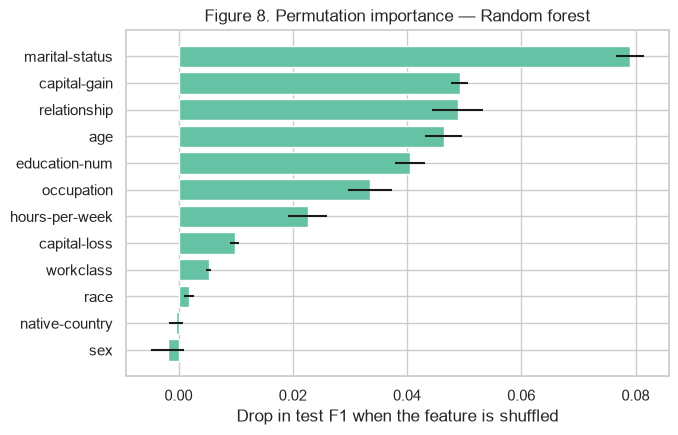

In [57]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, scoring="f1", n_repeats=5,
                              random_state=RANDOM_STATE)  # the forest itself already uses all cores
importance = (pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=X_test.columns)
              .sort_values("mean"))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index, importance["mean"], xerr=importance["std"], color="#66c2a5")
ax.set_xlabel("Drop in test F1 when the feature is shuffled")
ax.set_title(f"Figure 8. Permutation importance — {best_name}")
save(fig, "fig8_permutation_importance")
plt.show()

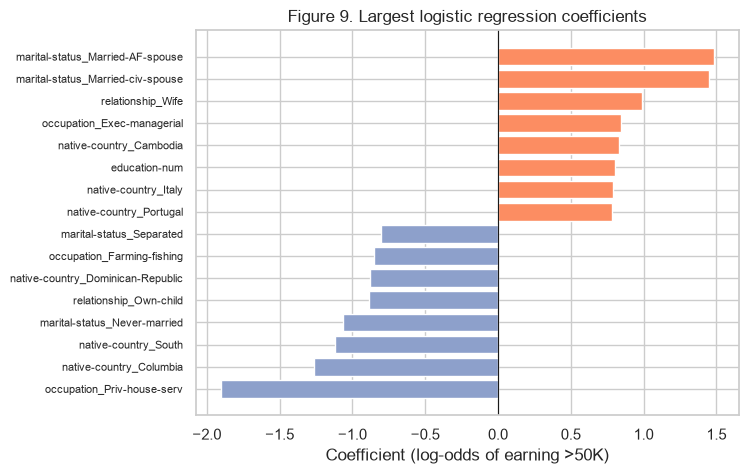

In [58]:
# Logistic regression coefficients: sign = direction of effect, size = strength (features are standardized)
coefs = pd.Series(log_reg.named_steps["model"].coef_[0],
                  index=log_reg.named_steps["prep"].get_feature_names_out())
coefs.index = coefs.index.str.replace(r"^(num|log|cat)__", "", regex=True)
top = pd.concat([coefs.nlargest(8), coefs.nsmallest(8)]).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#fc8d62", "#8da0cb"))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Coefficient (log-odds of earning >50K)")
ax.tick_params(axis="y", labelsize=8)
ax.set_title("Figure 9. Largest logistic regression coefficients")
save(fig, "fig9_lr_coefficients")
plt.show()

**What the models rely on.**
- **Strongest signals.** Both models agree that marital status / relationship, capital gains, age, education and occupation carry the most signal.
- **Married category.** "Married-civ-spouse" is the single strongest positive coefficient. This likely reflects household and life-stage effects (older, more established workers) rather than marriage itself causing higher income.
- **Sensitive attributes.** `sex` and `race` have almost no *direct* importance in the forest: shuffling them barely changes F1. This does **not** mean the model ignores sex, because `relationship` and `marital-status` carry much of the same information. Section 9 examines this.
- **Rare countries.** Several of the largest logistic regression coefficients belong to rare countries (for example Cambodia, Columbia), each with only a few dozen rows. These estimates are unreliable and should not be read as real effects.

## 9. Fairness Audit

A model can be accurate overall and still make errors unevenly across groups (Mehrabi et al., 2021). For the selected model, the following are compared for each sex and race group on the test set:

- **Selection rate.** Share of people predicted `>50K`.
- **True positive rate (TPR, recall).** Share of real high earners the model correctly finds. Equal TPR across groups is the *equal opportunity* criterion (Hardt et al., 2016).
- **False positive rate (FPR).** Share of people earning `<=50K` wrongly flagged as `>50K`.

Groups with few test rows produce unstable numbers, so group size is shown alongside each rate.

In [59]:
def group_metrics(y_true, y_pred, groups):
    """Per-group size, actual positive rate, selection rate, TPR, FPR and precision."""
    rows = {}
    for g in groups.dropna().unique():
        m = (groups == g).to_numpy()
        yt, yp = y_true[m], y_pred[m]
        rows[g] = {
            "n (test)": m.sum(),
            "Actual >50K rate": yt.mean(),
            "Selection rate": yp.mean(),
            "TPR (recall)": recall_score(yt, yp, zero_division=0),
            "FPR": ((yp == 1) & (yt == 0)).sum() / max((yt == 0).sum(), 1),
            "Precision": precision_score(yt, yp, zero_division=0),
        }
    return pd.DataFrame(rows).T.sort_values("n (test)", ascending=False)

def gaps(table):
    """Largest minus smallest value across groups for the key fairness rates."""
    cols = ["Selection rate", "TPR (recall)", "FPR"]
    return (table[cols].max() - table[cols].min())

y_pred_best = best_model.predict(X_test)
fmt = {"n (test)": "{:,.0f}", "Actual >50K rate": "{:.1%}", "Selection rate": "{:.1%}",
       "TPR (recall)": "{:.1%}", "FPR": "{:.1%}", "Precision": "{:.1%}"}

fair_sex = group_metrics(y_test.to_numpy(), y_pred_best, X_test["sex"])
fair_race = group_metrics(y_test.to_numpy(), y_pred_best, X_test["race"])
display(fair_sex.style.format(fmt).set_caption(f"{best_name}: metrics by sex"))
display(fair_race.style.format(fmt).set_caption(f"{best_name}: metrics by race"))

,n (test),Actual >50K rate,Selection rate,TPR (recall),FPR,Precision
Male,"6,480",30.4%,43.0%,85.6%,24.4%,60.5%
Female,"3,289",11.2%,11.1%,65.7%,4.3%,65.8%


,n (test),Actual >50K rate,Selection rate,TPR (recall),FPR,Precision
White,"8,348",25.4%,34.7%,83.5%,18.1%,61.1%
Black,944,12.8%,14.2%,69.4%,6.1%,62.7%
Asian-Pac-Islander,304,25.7%,31.6%,79.5%,15.0%,64.6%
Amer-Indian-Eskimo,104,8.7%,18.3%,66.7%,13.7%,31.6%
Other,69,15.9%,13.0%,63.6%,3.4%,77.8%


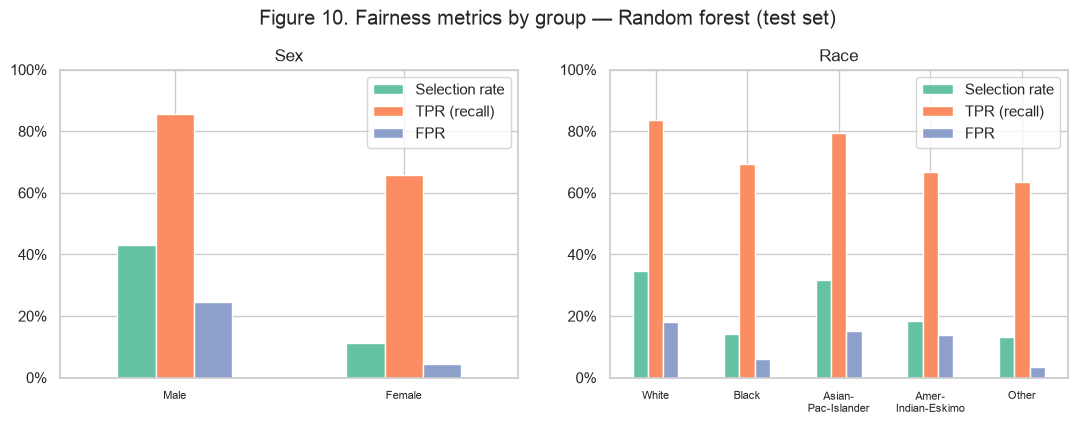

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (title, table) in zip(axes, [("Sex", fair_sex), ("Race", fair_race)]):
    table[["Selection rate", "TPR (recall)", "FPR"]].plot.bar(ax=ax, rot=0,
                                                              color=["#66c2a5", "#fc8d62", "#8da0cb"])
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.set_xticklabels([str(g).replace("-", "-\n", 1) for g in table.index], fontsize=8)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.suptitle(f"Figure 10. Fairness metrics by group — {best_name} (test set)", y=1.03)
save(fig, "fig10_fairness_by_group")
plt.show()

**Fairness findings.**
- **Selection rate by sex.** The model flags 43.0% of men but only 11.1% of women as `>50K`. For women this matches their actual rate in the data (11.2%). Men are over-flagged: 43.0% versus an actual 30.4%.
- **Unequal errors by sex.** The model finds **85.6% of high-earning men but only 65.7% of high-earning women**, a true-positive-rate gap of about 20 percentage points. Men also get far more false alarms (FPR 24.4% vs 4.3%). In short, the model is more "generous" to men and more likely to overlook women who do earn more than \$50K. This violates equal opportunity.
- **By race.** White and Asian-Pacific-Islander individuals have the highest TPR (83.5% and 79.5%). Black individuals have a lower TPR (69.4%) and a lower selection rate.
- **Small groups.** The `Amer-Indian-Eskimo` and `Other` groups have only 104 and 69 test rows, about 9 and 11 of whom are real high earners. Their rates can move by 10 points or more if one or two predictions change, so no firm conclusion can be drawn for them.

### 9.1 Mitigation experiment: removing sensitive attributes

A common first step is to stop the model from seeing protected attributes ("fairness through unawareness"). This is known to be insufficient when other features act as proxies (Mehrabi et al., 2021). Here `relationship` (`Husband`/`Wife`) is an obvious proxy for sex. Three versions of the selected model are retrained with the same hyperparameters and compared:

1. **All features** (the model above).
2. **Without `sex` and `race`.**
3. **Without `sex`, `race` and `relationship`.**

In [61]:
from sklearn.base import clone

variants = {
    "All features": [],
    "No sex/race": ["sex", "race"],
    "No sex/race/relationship": ["sex", "race", "relationship"],
}
best_estimator = best_model.named_steps["model"]

rows = []
for label, dropped in variants.items():
    cats = [c for c in cat_features if c not in dropped]
    model_v = make_pipeline(clone(best_estimator), num_features, cats)
    model_v.fit(X_train[num_features + cats], y_train)
    pred_v = model_v.predict(X_test[num_features + cats])
    perf = evaluate(model_v, X_test[num_features + cats], y_test)
    sex_gaps = gaps(group_metrics(y_test.to_numpy(), pred_v, X_test["sex"]))
    race_gaps = gaps(group_metrics(y_test.to_numpy(), pred_v, X_test["race"]))
    rows.append({"Variant": label, "F1": perf["F1"], "ROC-AUC": perf["ROC-AUC"],
                 "Sex: selection-rate gap": sex_gaps["Selection rate"],
                 "Sex: TPR gap": sex_gaps["TPR (recall)"],
                 "Sex: FPR gap": sex_gaps["FPR"],
                 "Race: TPR gap": race_gaps["TPR (recall)"]})

mitigation = pd.DataFrame(rows).set_index("Variant")
mitigation.style.format("{:.3f}")

,F1,ROC-AUC,Sex: selection-rate gap,Sex: TPR gap,Sex: FPR gap,Race: TPR gap
Variant,,,,,,
All features,0.702,0.918,0.319,0.199,0.201,0.198
No sex/race,0.700,0.919,0.309,0.191,0.191,0.159
No sex/race/relationship,0.700,0.919,0.309,0.199,0.190,0.155


**Mitigation result.**
- **Performance.** Removing `sex` and `race` leaves performance essentially unchanged (F1 0.702 to 0.700).
- **Sex gaps.** The sex-based gaps barely move: the TPR gap only falls from 0.199 to 0.191. Also removing `relationship` does not help either.
- **Race gap.** The race TPR gap shrinks somewhat (0.198 to 0.159), but this figure is dominated by the small groups noted above.
- **Why.** The remaining features (marital status, occupation, hours worked) still carry the patterns that differ by sex in the 1994 data. As expected, dropping the sensitive columns is not enough on its own (Mehrabi et al., 2021).

**Steps that would reduce the risk:**
1. Set group-specific decision thresholds that equalize true positive rates (a post-processing method; Hardt et al., 2016).
2. Reweight training examples so that each sex × income combination carries equal weight.
3. Report these group metrics with any use of the model, and never use it for consequential decisions about individuals (for example credit, hiring or benefits).

## 10. Summary

This notebook framed income prediction on the UCI Adult census data (48,842 people) as a supervised binary classification task: does a person earn more than \$50K a year? After cleaning and a leakage-safe preprocessing pipeline, a logistic regression and a random forest were tuned with 5-fold cross-validation using F1 as the selection metric, because only 24% of people are high earners. The random forest performed best on the held-out test set (F1 0.702, recall 0.825, precision 0.611, ROC-AUC 0.918), well ahead of a majority-class baseline that is 76% accurate but finds no high earners at all. Its strongest signals were marital status and relationship, capital gains, age and education. The main challenges were the class imbalance, mild overfitting in the forest (train F1 0.79 vs. cross-validated 0.70), and 30-year-old data. Most importantly, the model misses about a third of high-earning women but only one in seven high-earning men, and removing sex and race from the inputs did not close that gap because other features act as proxies.